In [2]:
try:
    import shap
    print("SHAP sudah terinstall")
    print("Versi SHAP:", shap.__version__)
except ImportError:
    print("SHAP belum terinstall")

SHAP sudah terinstall
Versi SHAP: 0.52.0


In [3]:
# ==========================================
# 1. IMPORT LIBRARY + AUTENTIKASI GEE
# ==========================================
import ee
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import shap
import matplotlib.pyplot as plt

# Autentikasi GEE
ee.Authenticate(
    auth_mode='colab',
    force=True
)

# Inisialisasi Cloud Project
ee.Initialize(project='ratihdwifardilah')

print("Semua library berhasil dipanggil")
print("Google Earth Engine berhasil terhubung")
print("Tes koneksi GEE:", ee.Number(1).getInfo())

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


Semua library berhasil dipanggil
Google Earth Engine berhasil terhubung
Tes koneksi GEE: 1


In [4]:
# ============================================================
# 2. DEFINE ROI & STUDY PERIOD
# KALIMANTAN BARAT | JULI-SEPTEMBER 2026
# ============================================================
# Region of Interest (ROI):
# Batas administrasi Provinsi Kalimantan Barat
# Sumber: Badan Informasi Geospasial (BIG), 2026

roi = ee.FeatureCollection(
    'projects/ratihdwifardilah/assets/Kalimantan_Barat_2026'
)

# Geometry ROI untuk proses spasial
roi_geom = roi.geometry()

# Periode pengamatan
# filterDate menggunakan tanggal akhir secara eksklusif,
# sehingga 2026-10-01 berarti data terakhir adalah 30 September 2026
start_date = '2026-07-01'
end_date   = '2026-10-01'

# Informasi awal
print("================================================")
print("MINI PROJECT KARHUTLA KALIMANTAN BARAT")
print("================================================")
print("Wilayah kajian       : Provinsi Kalimantan Barat")
print("Jumlah feature ROI   :", roi.size().getInfo())
print("Periode analisis     : 1 Juli - 30 September 2026")
print("Sumber batas wilayah : Badan Informasi Geospasial (BIG)")


MINI PROJECT KARHUTLA KALIMANTAN BARAT
Wilayah kajian       : Provinsi Kalimantan Barat
Jumlah feature ROI   : 1
Periode analisis     : 1 Juli - 30 September 2026
Sumber batas wilayah : Badan Informasi Geospasial (BIG)


In [7]:
# ============================================================
# 3. FEATURE ACQUISITION
# SENTINEL-5P + ERA5-LAND
# ============================================================
# A. SENTINEL-5P AEROSOL INDEX
# Parameter: Absorbing Aerosol Index
ai_raw = (
    ee.ImageCollection('COPERNICUS/S5P/NRTI/L3_AER_AI')
    .filterBounds(roi_geom)
    .filterDate(start_date, end_date)
)

ai_col = (
    ai_raw
    .select('absorbing_aerosol_index')
    .mean()
    .rename('Aerosol_Index')
    .clip(roi_geom)
)

# B. SENTINEL-5P NO2
# Parameter: NO2 Column Number Density
no2_raw = (
    ee.ImageCollection('COPERNICUS/S5P/NRTI/L3_NO2')
    .filterBounds(roi_geom)
    .filterDate(start_date, end_date)
)

no2_col = (
    no2_raw
    .select('NO2_column_number_density')
    .mean()
    .rename('NO2_Density')
    .clip(roi_geom)
)

# C. SENTINEL-5P HCHO
# Parameter: Tropospheric HCHO Column Number Density
hcho_raw = (
    ee.ImageCollection('COPERNICUS/S5P/NRTI/L3_HCHO')
    .filterBounds(roi_geom)
    .filterDate(start_date, end_date)
)

hcho_col = (
    hcho_raw
    .select('tropospheric_HCHO_column_number_density')
    .mean()
    .rename('HCHO_Density')
    .clip(roi_geom)
)

# D. ECMWF ERA5-LAND
# Parameter:
# 1. Temperature 2 meter
# 2. U-component of wind 10 meter
era5_raw = (
    ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR')
    .filterBounds(roi_geom)
    .filterDate(start_date, end_date)
)

era5_col = (
    era5_raw
    .select([
        'temperature_2m',
        'u_component_of_wind_10m'
    ])
    .mean()
    .rename([
        'Temperature_2m',
        'Wind_U'
    ])
    .clip(roi_geom)
)

print("Feature acquisition berhasil.")

Feature acquisition berhasil.


In [8]:
# ============================================================
# 4. CEK KETERSEDIAAN DATA
# ============================================================
print("================================================")
print("JUMLAH CITRA YANG DIGUNAKAN")
print("================================================")

print("Sentinel-5P Aerosol Index :", ai_raw.size().getInfo())
print("Sentinel-5P NO2           :", no2_raw.size().getInfo())
print("Sentinel-5P HCHO          :", hcho_raw.size().getInfo())
print("ERA5-Land                 :", era5_raw.size().getInfo())

JUMLAH CITRA YANG DIGUNAKAN
Sentinel-5P Aerosol Index : 807
Sentinel-5P NO2           : 571
Sentinel-5P HCHO          : 336
ERA5-Land                 : 92


In [9]:
# ===================================================================
# 5. LAYER STACKING
# Menggabungkan seluruh variabel prediktor menjadi satu image multiband
# ===================================================================
predictors = (
    ai_col
    .addBands(era5_col)
    .addBands(no2_col)
    .addBands(hcho_col)
)

print("=== BAND PREDIKTOR ===")

band_names = predictors.bandNames().getInfo()

for i, band in enumerate(band_names, start=1):
    print(f"{i}. {band}")

print("\nJumlah band prediktor:", len(band_names))

=== BAND PREDIKTOR ===
1. Aerosol_Index
2. Temperature_2m
3. Wind_U
4. NO2_Density
5. HCHO_Density

Jumlah band prediktor: 5


In [10]:
# ============================================================
# 6. RINGKASAN DATASET ESTIMASI PM2.5
# ============================================================
print("======================================================")
print("DATASET ESTIMASI PM2.5 KALIMANTAN BARAT")
print("======================================================")

print("\n1. Data Vektor / ROI")
print("   Wilayah          : Provinsi Kalimantan Barat")
print("   Sumber           : Badan Informasi Geospasial (BIG)")
print("   Edisi            : 2026")

print("\n2. Sentinel-5P")
print("   Aerosol Index    : COPERNICUS/S5P/NRTI/L3_AER_AI")
print("   NO2              : COPERNICUS/S5P/NRTI/L3_NO2")
print("   HCHO             : COPERNICUS/S5P/NRTI/L3_HCHO")

print("\n3. ECMWF ERA5-Land")
print("   Dataset          : ECMWF/ERA5_LAND/DAILY_AGGR")
print("   Parameter        : Temperature 2m")
print("                      U-component of wind 10m")

print("\n4. Periode Pengamatan")
print("   1 Juli - 30 September 2026")

print("\n5. Platform Pengolahan")
print("   Google Earth Engine")

DATASET ESTIMASI PM2.5 KALIMANTAN BARAT

1. Data Vektor / ROI
   Wilayah          : Provinsi Kalimantan Barat
   Sumber           : Badan Informasi Geospasial (BIG)
   Edisi            : 2026

2. Sentinel-5P
   Aerosol Index    : COPERNICUS/S5P/NRTI/L3_AER_AI
   NO2              : COPERNICUS/S5P/NRTI/L3_NO2
   HCHO             : COPERNICUS/S5P/NRTI/L3_HCHO

3. ECMWF ERA5-Land
   Dataset          : ECMWF/ERA5_LAND/DAILY_AGGR
   Parameter        : Temperature 2m
                      U-component of wind 10m

4. Periode Pengamatan
   1 Juli - 30 September 2026

5. Platform Pengolahan
   Google Earth Engine


In [11]:
# ============================================================
# 7. RANDOM POINTS & SAMPLE REGIONS
# Ekstraksi nilai piksel seluruh variabel prediktor
# ============================================================
# Membuat 1.500 titik sampel acak di dalam ROI Kalimantan Barat
random_points = ee.FeatureCollection.randomPoints(
    region=roi_geom,
    points=1500,
    seed=42
)

print(
    "Jumlah titik sampel:",
    random_points.size().getInfo()
)

# Mengekstrak nilai seluruh band prediktor pada titik sampel
sampled = predictors.sampleRegions(
    collection=random_points,
    scale=5500,
    geometries=True
)

print(
    "Jumlah sampel hasil ekstraksi:",
    sampled.size().getInfo()
)

Jumlah titik sampel: 1500
Jumlah sampel hasil ekstraksi: 1486


In [12]:
# ============================================================
# 8. DATA PREPROCESSING
# ============================================================
# Mengambil hasil sampling dari GEE ke Python
sampled_list = sampled.getInfo()['features']

# Fungsi untuk mengambil nilai property
def get_value(props, possible_names, default=None):
    for name in possible_names:
        if name in props and props[name] is not None:
            return props[name]
    return default

data = []

for feature in sampled_list:

    props = feature.get('properties', {})
    geometry = feature.get('geometry', {})
    coords = geometry.get('coordinates', [None, None])

    row = {
        'longitude': coords[0],
        'latitude': coords[1],

        'Aerosol_Index': get_value(
            props,
            ['Aerosol_Index', 'absorbing_aerosol_index']
        ),

        'Temperature_2m': get_value(
            props,
            ['Temperature_2m', 'temperature_2m']
        ),

        'Wind_U': get_value(
            props,
            ['Wind_U', 'u_component_of_wind_10m']
        ),

        'NO2_Density': get_value(
            props,
            [
                'NO2_Density',
                'NO2_column_number_density'
            ]
        ),

        'HCHO_Density': get_value(
            props,
            [
                'HCHO_Density',
                'tropospheric_HCHO_column_number_density'
            ]
        )
    }

    # Simpan hanya baris dengan seluruh prediktor lengkap
    if all([
        row['longitude'] is not None,
        row['latitude'] is not None,
        row['Aerosol_Index'] is not None,
        row['Temperature_2m'] is not None,
        row['Wind_U'] is not None,
        row['NO2_Density'] is not None,
        row['HCHO_Density'] is not None
    ]):
        data.append(row)

# Konversi ke Pandas DataFrame
df = pd.DataFrame(data)

print("========================================")
print("HASIL DATA PREPROCESSING")
print("========================================")
print("Jumlah sampel dari GEE :", len(sampled_list))
print("Jumlah data valid      :", len(df))
print("Jumlah kolom           :", len(df.columns))

print("\nDaftar kolom:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\n5 data pertama:")
display(df.head())

HASIL DATA PREPROCESSING
Jumlah sampel dari GEE : 1486
Jumlah data valid      : 1486
Jumlah kolom           : 7

Daftar kolom:
['longitude', 'latitude', 'Aerosol_Index', 'Temperature_2m', 'Wind_U', 'NO2_Density', 'HCHO_Density']

Missing values:
longitude         0
latitude          0
Aerosol_Index     0
Temperature_2m    0
Wind_U            0
NO2_Density       0
HCHO_Density      0
dtype: int64

5 data pertama:


,longitude,latitude,Aerosol_Index,Temperature_2m,Wind_U,NO2_Density,HCHO_Density
0,111.290035,-0.419962,-0.371444,300.041819,-0.261247,0.000046,0.000118
1,110.301888,-1.012850,-0.026775,301.441462,-0.373022,0.000053,0.000189
2,111.487664,0.469370,-0.191580,301.000995,-0.115934,0.000050,0.000150
3,111.092405,-0.074111,-0.052693,301.055865,-0.117150,0.000051,0.000201
4,112.722848,-0.321148,-0.016745,300.321796,-0.580103,0.000051,0.000132


In [15]:
# ============================================================
# 9. PEMBENTUKAN TARGET SIMULASI PM2.5
# Mock Ground Truth
# ============================================================
np.random.seed(42)

# Konversi suhu ERA5-Land dari Kelvin ke Celsius
temperature_c = df['Temperature_2m'] - 273.15

# Koefisien simulasi
B0 = 30.0
B1 = 45.0
B2 = 400000
B3 = 0.1
B4 = -2.0

noise = np.random.normal(
    0,
    3,
    len(df)
)

df['Actual_PM25'] = (
    B0
    + (B1 * df['Aerosol_Index'])
    + (B2 * df['NO2_Density'])
    + (B3 * temperature_c)
    + (B4 * df['Wind_U'])
    + noise
)

# Mencegah nilai simulasi negatif
df['Actual_PM25'] = df['Actual_PM25'].abs()

print("========================================")
print("TARGET SIMULASI PM2.5 BERHASIL DIBUAT")
print("========================================")
print("Jenis target : Mock Ground Truth / simulasi")
print("Jumlah data  :", len(df))

print("\n5 data pertama:")
display(
    df[
        [
            'Aerosol_Index',
            'Temperature_2m',
            'Wind_U',
            'NO2_Density',
            'Actual_PM25'
        ]
    ].head()
)

TARGET SIMULASI PM2.5 BERHASIL DIBUAT
Jenis target : Mock Ground Truth / simulasi
Jumlah data  : 1486

5 data pertama:


,Aerosol_Index,Temperature_2m,Wind_U,NO2_Density,Actual_PM25
0,-0.371444,300.041819,-0.261247,0.000046,36.408249
1,-0.026775,301.441462,-0.373022,0.000053,53.088774
2,-0.191580,301.000995,-0.115934,0.000050,46.276730
3,-0.052693,301.055865,-0.117150,0.000051,55.667202
4,-0.016745,300.321796,-0.580103,0.000051,52.738394


In [16]:
# ============================================================
# 10. TRAIN / TEST SPLIT
# ============================================================
features = [
    'Aerosol_Index',
    'Temperature_2m',
    'Wind_U',
    'NO2_Density',
    'HCHO_Density'
]

X = df[features]
y = df['Actual_PM25']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Jumlah data total :", len(df))
print("Training dataset :", len(X_train))
print("Testing dataset  :", len(X_test))

Jumlah data total : 1486
Training dataset : 1188
Testing dataset  : 298


In [17]:
# ============================================================
# 11. RANDOM FOREST REGRESSION
# ============================================================
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred = rf_model.predict(X_test)

print("Model Random Forest berhasil dilatih.")

Model Random Forest berhasil dilatih.


HASIL EVALUASI RANDOM FOREST
RMSE : 3.356
R²   : 0.948


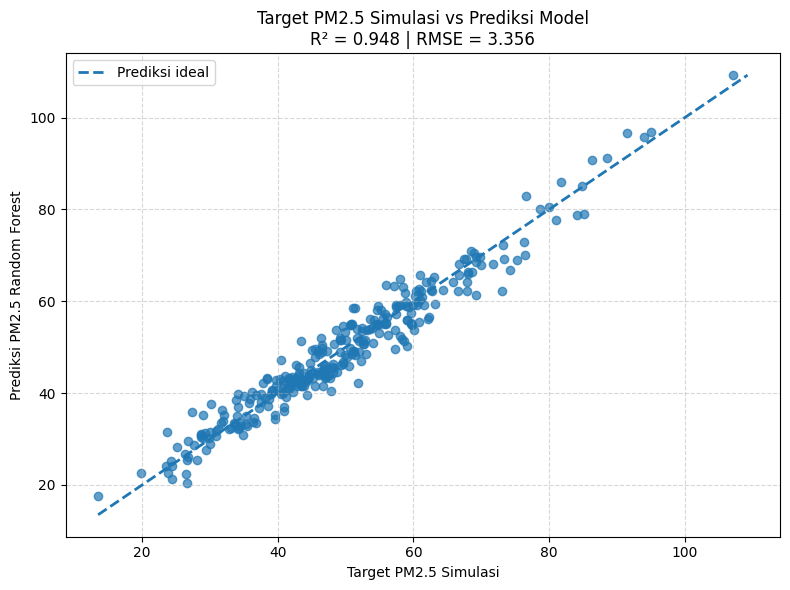

In [18]:
# ============================================================
# 12. MODEL EVALUATION
# ============================================================
rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(
    y_test, y_pred
)

print("========================================")
print("HASIL EVALUASI RANDOM FOREST")
print("========================================")
print(f"RMSE : {rmse:.3f}")
print(f"R²   : {r2:.3f}")

# ============================================================
# VISUALISASI KINERJA MODEL
# ============================================================
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7
)

min_val = min(
    y_test.min(),
    y_pred.min()
)

max_val = max(
    y_test.max(),
    y_pred.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle='--',
    linewidth=2,
    label='Prediksi ideal'
)

plt.xlabel("Target PM2.5 Simulasi")
plt.ylabel("Prediksi PM2.5 Random Forest")

plt.title(
    f"Target PM2.5 Simulasi vs Prediksi Model\n"
    f"R² = {r2:.3f} | RMSE = {rmse:.3f}"
)

plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Menampilkan SHAP Summary Plot...


/tmp/ipykernel_6326/1084176812.py:9: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


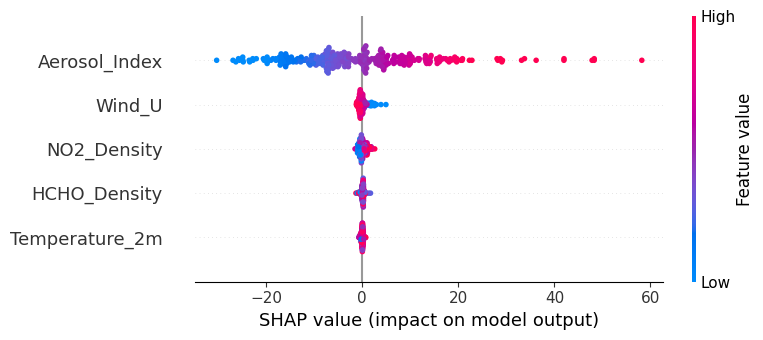

In [19]:
# ============================================================
# 13. SHAP FEATURE IMPORTANCE
# ============================================================
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test)

print("Menampilkan SHAP Summary Plot...")

shap.summary_plot(
    shap_values,
    X_test,
    feature_names=features
)

In [20]:
# ============================================================
# 14. SPATIAL PREDICTION DATA PREPARATION
# ============================================================
# Memastikan urutan band sama dengan fitur model Random Forest
predictor_image = (
    predictors
    .select(features)
    .clip(roi_geom)
)

print("Band prediktor:")
print(predictor_image.bandNames().getInfo())

# Mengambil nilai seluruh variabel prediktor secara spasial
# pada wilayah Kalimantan Barat
spatial_samples = predictor_image.sample(
    region=roi_geom,
    scale=5500,
    geometries=True,
    dropNulls=True,
    tileScale=4
)

print(
    "Jumlah sampel spasial:",
    spatial_samples.size().getInfo()
)

Band prediktor:
['Aerosol_Index', 'Temperature_2m', 'Wind_U', 'NO2_Density', 'HCHO_Density']
Jumlah sampel spasial: 4838


In [21]:
# ============================================================
# 15. RANDOM FOREST SPATIAL PREDICTION
# ============================================================
# Mengambil hasil sampling spasial dari GEE
spatial_info = spatial_samples.getInfo()
spatial_data = []

for feature in spatial_info['features']:

    props = feature.get('properties', {})
    geometry = feature.get('geometry', {})
    coords = geometry.get('coordinates', [None, None])

    row = {
        'longitude': coords[0],
        'latitude': coords[1],
        'Aerosol_Index': props.get('Aerosol_Index'),
        'Temperature_2m': props.get('Temperature_2m'),
        'Wind_U': props.get('Wind_U'),
        'NO2_Density': props.get('NO2_Density'),
        'HCHO_Density': props.get('HCHO_Density')
    }

    spatial_data.append(row)

# Konversi menjadi DataFrame
spatial_df = pd.DataFrame(spatial_data)

# Bersihkan nilai kosong
spatial_df = spatial_df.dropna(
    subset=['longitude', 'latitude'] + features
).copy()

# Prediksi PM2.5 menggunakan model Random Forest
spatial_df['Predicted_PM25'] = rf_model.predict(
    spatial_df[features]
)

print("========================================")
print("HASIL PREDIKSI SPASIAL PM2.5")
print("========================================")
print("Jumlah titik prediksi :", len(spatial_df))

print("\nStatistik Predicted PM2.5:")
print(spatial_df['Predicted_PM25'].describe())

print("\n5 data pertama:")
display(spatial_df.head())

HASIL PREDIKSI SPASIAL PM2.5
Jumlah titik prediksi : 4838

Statistik Predicted PM2.5:
count    4838.000000
mean       48.911504
std        14.589739
min        12.887937
25%        40.283303
50%        47.072022
75%        56.762875
max       111.856879
Name: Predicted_PM25, dtype: float64

5 data pertama:


,longitude,latitude,Aerosol_Index,Temperature_2m,Wind_U,NO2_Density,HCHO_Density,Predicted_PM25
0,110.697147,-2.989144,-0.368956,300.741779,-4.587328,0.000050,0.000131,39.670334
1,110.301888,-2.939737,-0.218298,300.685598,-5.620279,0.000049,0.000119,51.424673
2,110.697147,-2.939737,-0.298029,300.822546,-3.888359,0.000051,0.000155,44.120279
3,110.746554,-2.939737,-0.194365,300.822546,-3.888359,0.000054,0.000143,50.912641
4,110.252481,-2.890329,-0.093777,300.685598,-5.620279,0.000050,0.000134,52.748183


In [22]:
# ============================================================
# 16. PREPARASI HASIL ESTIMASI PM2.5 UNTUK PEMETAAN
# ============================================================
# Menyimpan nilai prediksi asli dari Random Forest
spatial_df['Predicted_PM25_Raw'] = spatial_df['Predicted_PM25']

# Pengaman untuk pemetaan:
# nilai prediksi negatif, jika ada, dibatasi menjadi 0
spatial_df['PM25_Map'] = (
    spatial_df['Predicted_PM25_Raw']
    .clip(lower=0)
)

print("========================================")
print("STATISTIK ESTIMASI PM2.5 UNTUK PEMETAAN")
print("========================================")

print(spatial_df['PM25_Map'].describe())

print(
    "\nJumlah prediksi negatif:",
    (spatial_df['Predicted_PM25_Raw'] < 0).sum()
)

STATISTIK ESTIMASI PM2.5 UNTUK PEMETAAN
count    4838.000000
mean       48.911504
std        14.589739
min        12.887937
25%        40.283303
50%        47.072022
75%        56.762875
max       111.856879
Name: PM25_Map, dtype: float64

Jumlah prediksi negatif: 0


In [23]:
# ============================================================
# 17. MENGAMBIL GEOMETRI BATAS KALIMANTAN BARAT
# ============================================================
# Mengambil geometri ROI dari GEE ke Python utk kebutuhan visualisasi peta
roi_geometry = roi_geom.getInfo()

print("========================================")
print("GEOMETRI ROI KALIMANTAN BARAT")
print("========================================")
print("Tipe geometri :", roi_geometry['type'])
print("Geometry keys :", roi_geometry.keys())

GEOMETRI ROI KALIMANTAN BARAT
Tipe geometri : GeometryCollection
Geometry keys : dict_keys(['type', 'geometries'])


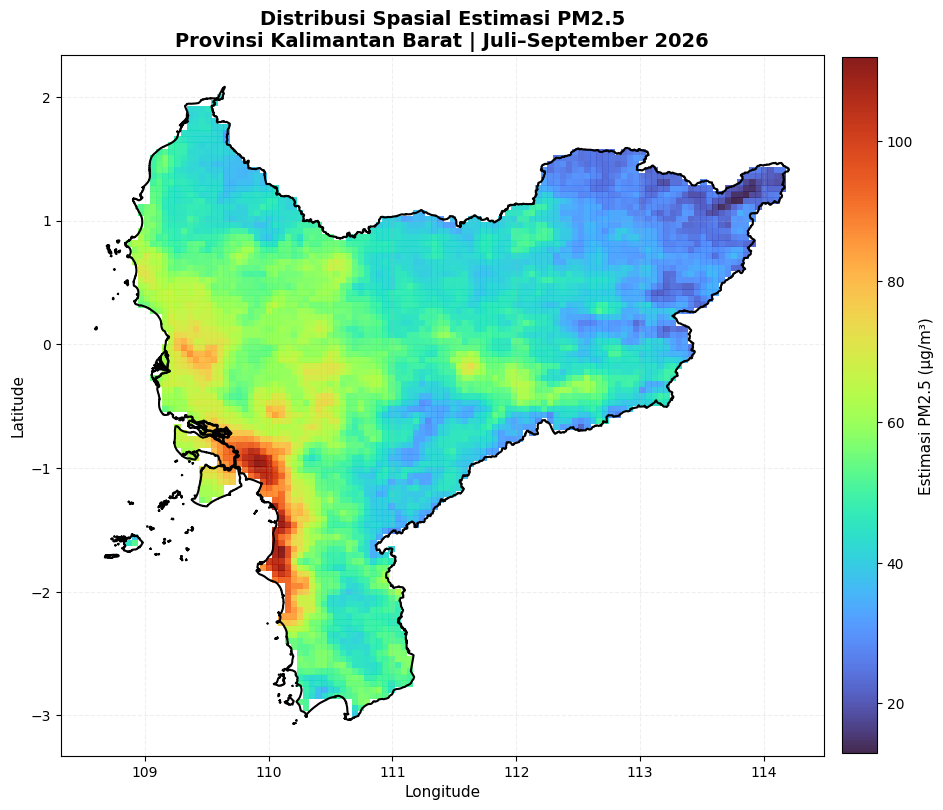

Peta distribusi estimasi PM2.5 berhasil dibuat.


In [25]:
# ============================================================
# 18. VISUALISASI DISTRIBUSI SPASIAL ESTIMASI PM2.5
# ============================================================
# Fungsi untuk menggambar batas administrasi
# ------------------------------------------------------------
def plot_gee_boundary(ax, geometry, linewidth=1.5):

    geom_type = geometry.get('type')

    if geom_type == 'GeometryCollection':

        for geom in geometry.get('geometries', []):
            plot_gee_boundary(
                ax,
                geom,
                linewidth
            )

    elif geom_type in ['Polygon', 'MultiPolygon']:

        coords = geometry['coordinates']

        polygons = (
            [coords]
            if geom_type == 'Polygon'
            else coords
        )

        for polygon in polygons:

            for ring in polygon:

                ax.plot(
                    [p[0] for p in ring],
                    [p[1] for p in ring],
                    color='black',
                    linewidth=linewidth
                )

    elif geom_type in ['LineString', 'LinearRing']:

        coords = geometry['coordinates']

        ax.plot(
            [p[0] for p in coords],
            [p[1] for p in coords],
            color='black',
            linewidth=linewidth
        )

    elif geom_type == 'MultiLineString':

        for line in geometry['coordinates']:

            plot_gee_boundary(
                ax,
                {
                    'type': 'LineString',
                    'coordinates': line
                },
                linewidth
            )

# ------------------------------------------------------------
# Membuat peta distribusi estimasi PM2.5
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(10, 9)
)

pm25_plot = ax.scatter(
    spatial_df['longitude'],
    spatial_df['latitude'],
    c=spatial_df['PM25_Map'],
    cmap='turbo',
    marker='s',
    s=22,
    linewidths=0,
    alpha=0.90
)

# Menambahkan batas administrasi Kalimantan Barat
plot_gee_boundary(
    ax,
    roi_geometry,
    linewidth=1.5
)

# Colorbar
cbar = plt.colorbar(
    pm25_plot,
    ax=ax,
    shrink=0.80,
    pad=0.02
)

cbar.set_label(
    'Estimasi PM2.5 (µg/m³)',
    fontsize=11
)

# Judul dan keterangan peta
ax.set_title(
    'Distribusi Spasial Estimasi PM2.5\n'
    'Provinsi Kalimantan Barat | Juli–September 2026',
    fontsize=14,
    fontweight='bold'
)

ax.set_xlabel(
    'Longitude',
    fontsize=11
)

ax.set_ylabel(
    'Latitude',
    fontsize=11
)

ax.grid(
    alpha=0.20,
    linestyle='--'
)

ax.set_aspect(
    'equal',
    adjustable='box'
)

plt.tight_layout()
plt.show()

print("Peta distribusi estimasi PM2.5 berhasil dibuat.")

In [26]:
# ============================================================
# 19. IDENTIFIKASI ZONA ESTIMASI PM2.5 RELATIF TINGGI
# ============================================================
# Threshold relatif menggunakan persentil ke-75 (Q75)
pm25_q75 = spatial_df['PM25_Map'].quantile(0.75)

# Menandai titik dengan estimasi PM2.5 >= Q75
spatial_df['High_PM25'] = (
    spatial_df['PM25_Map'] >= pm25_q75
)

# Statistik zona relatif tinggi
n_total = len(spatial_df)
n_high = spatial_df['High_PM25'].sum()
percent_high = (n_high / n_total) * 100

print("========================================")
print("ZONA ESTIMASI PM2.5 RELATIF TINGGI")
print("========================================")
print(f"Threshold Q75         : {pm25_q75:.3f}")
print(f"Jumlah titik total    : {n_total}")
print(f"Titik zona tinggi     : {n_high}")
print(f"Persentase titik      : {percent_high:.2f}%")

ZONA ESTIMASI PM2.5 RELATIF TINGGI
Threshold Q75         : 56.763
Jumlah titik total    : 4838
Titik zona tinggi     : 1210
Persentase titik      : 25.01%


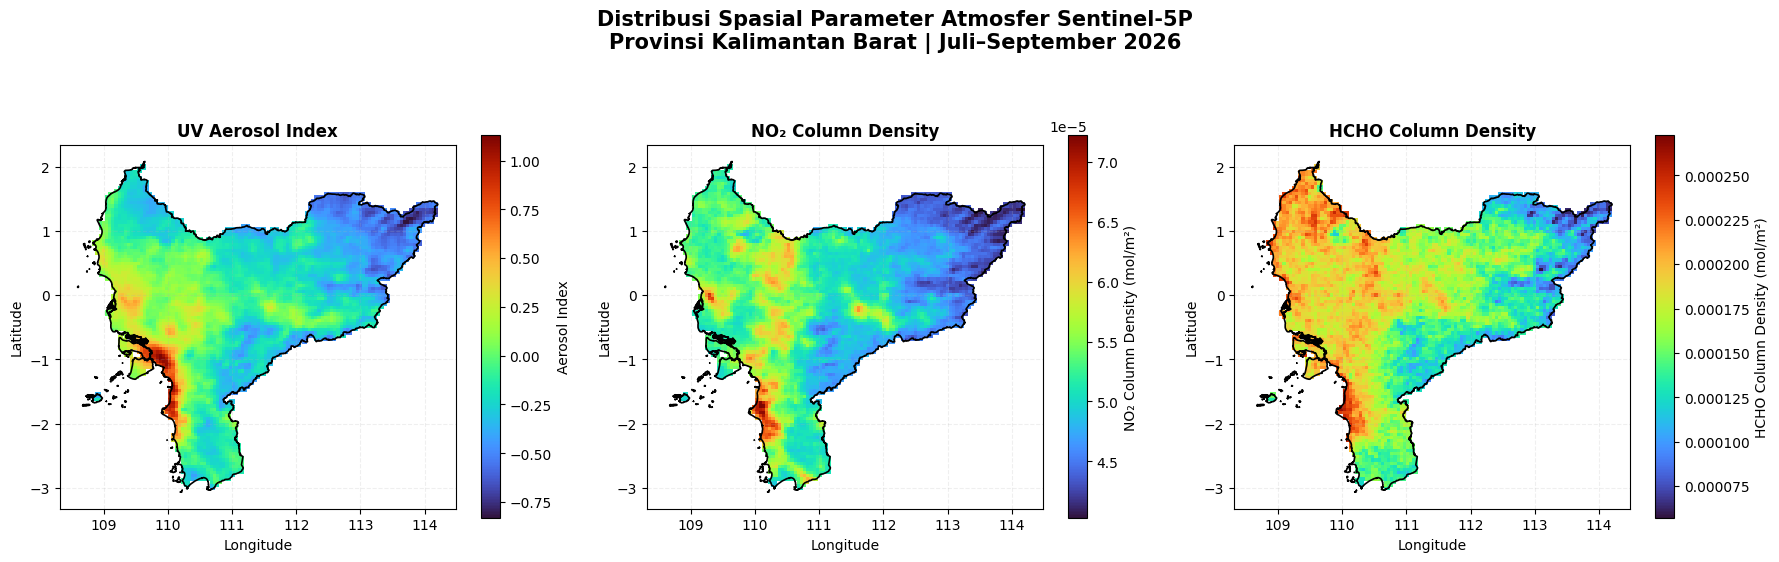

Visualisasi Aerosol Index, NO2, dan HCHO berhasil dibuat.


In [29]:
# ============================================================
# 20. VISUALISASI PARAMETER ATMOSFER SENTINEL-5P
# Aerosol Index, NO2, dan HCHO
# ============================================================
fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

# ------------------------------------------------------------
# 1. AEROSOL INDEX
# ------------------------------------------------------------
plot_ai = axes[0].scatter(
    spatial_df['longitude'],
    spatial_df['latitude'],
    c=spatial_df['Aerosol_Index'],
    cmap='turbo',
    marker='s',
    s=18,
    linewidths=0
)

plot_gee_boundary(
    axes[0],
    roi_geometry,
    linewidth=1.2
)

cbar_ai = plt.colorbar(
    plot_ai,
    ax=axes[0],
    shrink=0.75
)

cbar_ai.set_label(
    'Aerosol Index'
)

axes[0].set_title(
    'UV Aerosol Index',
    fontweight='bold'
)

axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')

axes[0].grid(
    alpha=0.2,
    linestyle='--'
)

axes[0].set_aspect(
    'equal',
    adjustable='box'
)

# ------------------------------------------------------------
# 2. NO2 COLUMN DENSITY
# ------------------------------------------------------------
plot_no2 = axes[1].scatter(
    spatial_df['longitude'],
    spatial_df['latitude'],
    c=spatial_df['NO2_Density'],
    cmap='turbo',
    marker='s',
    s=18,
    linewidths=0
)

plot_gee_boundary(
    axes[1],
    roi_geometry,
    linewidth=1.2
)

cbar_no2 = plt.colorbar(
    plot_no2,
    ax=axes[1],
    shrink=0.75
)

cbar_no2.set_label(
    'NO₂ Column Density (mol/m²)'
)

axes[1].set_title(
    'NO₂ Column Density',
    fontweight='bold'
)

axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')

axes[1].grid(
    alpha=0.2,
    linestyle='--'
)

axes[1].set_aspect(
    'equal',
    adjustable='box'
)

# ------------------------------------------------------------
# 3. HCHO COLUMN DENSITY
# ------------------------------------------------------------
plot_hcho = axes[2].scatter(
    spatial_df['longitude'],
    spatial_df['latitude'],
    c=spatial_df['HCHO_Density'],
    cmap='turbo',
    marker='s',
    s=18,
    linewidths=0
)

plot_gee_boundary(
    axes[2],
    roi_geometry,
    linewidth=1.2
)

cbar_hcho = plt.colorbar(
    plot_hcho,
    ax=axes[2],
    shrink=0.75
)

cbar_hcho.set_label(
    'HCHO Column Density (mol/m²)'
)

axes[2].set_title(
    'HCHO Column Density',
    fontweight='bold'
)

axes[2].set_xlabel('Longitude')
axes[2].set_ylabel('Latitude')

axes[2].grid(
    alpha=0.2,
    linestyle='--'
)

axes[2].set_aspect(
    'equal',
    adjustable='box'
)

# ------------------------------------------------------------
# Judul utama
# ------------------------------------------------------------
fig.suptitle(
    'Distribusi Spasial Parameter Atmosfer Sentinel-5P\n'
    'Provinsi Kalimantan Barat | Juli–September 2026',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

print(
    "Visualisasi Aerosol Index, NO2, dan HCHO berhasil dibuat."
)

In [30]:
# ============================================================
# 21. WORLDPOP POPULATION DATA PREPARATION
# Baseline populasi Indonesia tahun 2020
# ============================================================
# Mengambil data WorldPop Indonesia
worldpop_collection = (
    ee.ImageCollection('WorldPop/GP/100m/pop')
    .filter(ee.Filter.eq('country', 'IDN'))
    .filter(ee.Filter.eq('year', 2020))
)

print("========================================")
print("WORLDPOP DATA PREPARATION")
print("========================================")
print(
    "Jumlah image WorldPop:",
    worldpop_collection.size().getInfo()
)

# Mengambil raster populasi tahun 2020
population = (
    ee.Image(worldpop_collection.first())
    .select('population')
    .rename('Population')
    .clip(roi_geom)
)

# Informasi raster
population_projection = population.projection()

print(
    "Band populasi:",
    population.bandNames().getInfo()
)

print(
    "Proyeksi:",
    population_projection.crs().getInfo()
)

print(
    "Resolusi nominal (meter):",
    population_projection.nominalScale().getInfo()
)

print("WorldPop Indonesia 2020 berhasil disiapkan.")

WORLDPOP DATA PREPARATION
Jumlah image WorldPop: 1
Band populasi: ['Population']
Proyeksi: EPSG:4326
Resolusi nominal (meter): 92.76624195687849
WorldPop Indonesia 2020 berhasil disiapkan.


In [31]:
# ============================================================
# 22. MEMBENTUK ZONA PM2.5 RELATIF TINGGI DI GEE
# Untuk analisis paparan populasi
# ============================================================
# Mengambil titik yang termasuk zona PM2.5 relatif tinggi
high_pm25_df = spatial_df[
    spatial_df['High_PM25']
].copy()

print("========================================")
print("PREPARASI ZONA PM2.5 RELATIF TINGGI")
print("========================================")
print("Threshold Q75      :", round(pm25_q75, 3))
print("Jumlah titik tinggi:", len(high_pm25_df))

# ------------------------------------------------------------
# Mengubah titik PM2.5 tinggi dari Pandas ke GEE FeatureCollection
# ------------------------------------------------------------
high_features = []

for _, row in high_pm25_df.iterrows():

    point = ee.Geometry.Point(
        [
            float(row['longitude']),
            float(row['latitude'])
        ]
    )

    feature = ee.Feature(
        point,
        {
            'PM25': float(row['PM25_Map'])
        }
    )

    high_features.append(feature)

high_pm25_fc = ee.FeatureCollection(high_features)

# ------------------------------------------------------------
# Membentuk raster zona relatif tinggi
# Titik prediksi memiliki interval analisis ±5.5 km.
# Kernel persegi 2.75 km digunakan untuk merepresentasikan
# area di sekitar masing-masing titik grid.
# ------------------------------------------------------------
high_point_image = (
    ee.Image(0)
    .byte()
    .paint(high_pm25_fc, 1)
)

high_pm25_mask = (
    high_point_image
    .reduceNeighborhood(
        reducer=ee.Reducer.max(),
        kernel=ee.Kernel.square(
            radius=2750,
            units='meters'
        )
    )
    .eq(1)
    .selfMask()
    .clip(roi_geom)
)

print(
    "Jumlah feature zona tinggi:",
    high_pm25_fc.size().getInfo()
)

print("Mask zona PM2.5 relatif tinggi berhasil dibuat.")

PREPARASI ZONA PM2.5 RELATIF TINGGI
Threshold Q75      : 56.763
Jumlah titik tinggi: 1210


Jumlah feature zona tinggi: 1210
Mask zona PM2.5 relatif tinggi berhasil dibuat.


In [33]:
# ============================================================
# 23. ESTIMASI PAPARAN POPULASI
# WORLDPOP 2020 | ZONA PM2.5 RELATIF TINGGI
# ============================================================
# 1. Konversi WorldPop menjadi kepadatan penduduk
#    (jiwa per meter persegi)
worldpop_projection = population.projection()

native_pixel_area = (
    ee.Image.pixelArea()
    .reproject(worldpop_projection)
)

population_density = (
    population
    .divide(native_pixel_area)
    .rename('Population_Density')
)

# 2. Agregasi kepadatan WorldPop ke skala analisis 5.5 km
#
# Mean digunakan untuk mempertahankan kepadatan,
# kemudian dikalikan luas piksel pada skala analisis
population_density_5500 = (
    population_density
    .reduceResolution(
        reducer=ee.Reducer.mean(),
        maxPixels=4096
    )
)

population_5500 = (
    population_density_5500
    .multiply(ee.Image.pixelArea())
    .rename('Population_5500')
)

# 3. Bentuk zona PM2.5 relatif tinggi
#
# Titik Q75 diberi buffer 2.75 km
# (setengah dari grid analisis 5.5 km)
high_zone_fc = high_pm25_fc.map(
    lambda feature: feature.buffer(2750)
)

high_zone_mask = (
    ee.Image(0)
    .byte()
    .paint(high_zone_fc, 1)
    .selfMask()
    .clip(roi_geom)
)

# 4. Total populasi Kalimantan Barat
total_population_dict = population_5500.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=roi_geom,
    crs='EPSG:3857',
    scale=5500,
    maxPixels=1e7,
    tileScale=16
)

total_population = (
    ee.Number(
        total_population_dict.get('Population_5500')
    )
    .getInfo()
)

# 5. Populasi pada zona PM2.5 relatif tinggi
population_high = (
    population_5500
    .updateMask(high_zone_mask)
)

high_population_dict = population_high.reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=roi_geom,
    crs='EPSG:3857',
    scale=5500,
    maxPixels=1e7,
    tileScale=16
)

high_population = (
    ee.Number(
        high_population_dict.get('Population_5500')
    )
    .getInfo()
)

# 6. Persentase estimasi paparan
exposure_percent = (
    high_population / total_population * 100
    if total_population > 0
    else 0
)

# 7. HASIL
print("========================================")
print("ESTIMASI PAPARAN POPULASI PM2.5")
print("========================================")

print(
    f"Total populasi WorldPop       : "
    f"{total_population:,.0f} jiwa"
)

print(
    f"Populasi zona PM2.5 tinggi    : "
    f"{high_population:,.0f} jiwa"
)

print(
    f"Persentase estimasi paparan   : "
    f"{exposure_percent:.2f}%"
)

print(
    f"Threshold PM2.5 Q75           : "
    f"{pm25_q75:.3f}"
)

ESTIMASI PAPARAN POPULASI PM2.5
Total populasi WorldPop       : 5,247,615 jiwa
Populasi zona PM2.5 tinggi    : 2,544,996 jiwa
Persentase estimasi paparan   : 48.50%
Threshold PM2.5 Q75           : 56.763


,Kategori,Jumlah Penduduk
0,Total Populasi WorldPop,"5,247,615"
1,Populasi Zona PM2.5 Relatif Tinggi,"2,544,996"


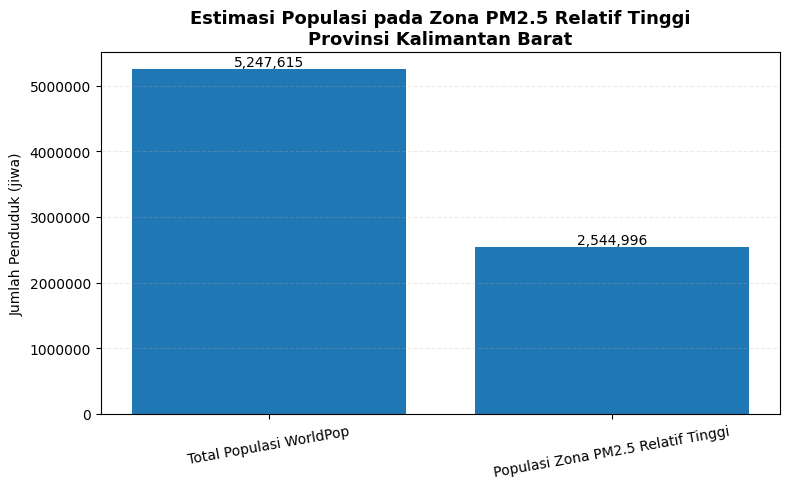

RINGKASAN ESTIMASI PAPARAN POPULASI
Total populasi WorldPop                : 5,247,615 jiwa
Populasi zona PM2.5 relatif tinggi     : 2,544,996 jiwa
Persentase estimasi paparan            : 48.50%
Threshold Q75                          : 56.763


In [36]:
# ============================================================
# 24. VISUALISASI ESTIMASI PAPARAN POPULASI
# KALIMANTAN BARAT | JULI-SEPTEMBER 2026
# ============================================================
population_summary = pd.DataFrame({
    'Kategori': [
        'Total Populasi WorldPop',
        'Populasi Zona PM2.5 Relatif Tinggi'
    ],
    'Jumlah Penduduk': [
        total_population,
        high_population
    ]
})

display(
    population_summary.style.format({
        'Jumlah Penduduk': '{:,.0f}'
    })
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    population_summary['Kategori'],
    population_summary['Jumlah Penduduk']
)

ax.set_title(
    'Estimasi Populasi pada Zona PM2.5 Relatif Tinggi\n'
    'Provinsi Kalimantan Barat',
    fontsize=13,
    fontweight='bold'
)

ax.set_ylabel('Jumlah Penduduk (jiwa)')

ax.ticklabel_format(
    style='plain',
    axis='y'
)

ax.grid(
    axis='y',
    alpha=0.25,
    linestyle='--'
)

for bar in bars:
    value = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:,.0f}',
        ha='center',
        va='bottom'
    )

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

print("========================================")
print("RINGKASAN ESTIMASI PAPARAN POPULASI")
print("========================================")
print(f"Total populasi WorldPop                : {total_population:,.0f} jiwa")
print(f"Populasi zona PM2.5 relatif tinggi     : {high_population:,.0f} jiwa")
print(f"Persentase estimasi paparan            : {exposure_percent:.2f}%")
print(f"Threshold Q75                          : {pm25_q75:.3f}")

In [38]:
# ============================================================
# 25. MENYIMPAN HASIL ANALISIS UNTUK DASHBOARD
# ============================================================
# 1. DATA SPASIAL PM2.5 DAN PARAMETER ATMOSFER
dashboard_data = spatial_df[
    [
        'longitude',
        'latitude',
        'Aerosol_Index',
        'Temperature_2m',
        'Wind_U',
        'NO2_Density',
        'HCHO_Density',
        'PM25_Map',
        'High_PM25'
    ]
].copy()

dashboard_data.to_csv(
    'pm25_spatial_kalbar.csv',
    index=False
)

# 2. RINGKASAN HASIL ANALISIS
dashboard_summary = pd.DataFrame({
    'Parameter': [
        'RMSE',
        'R2',
        'Threshold_Q75',
        'Total_Population',
        'High_PM25_Population',
        'Exposure_Percent'
    ],
    'Value': [
        rmse,
        r2,
        pm25_q75,
        total_population,
        high_population,
        exposure_percent
    ]
})

dashboard_summary.to_csv(
    'pm25_summary_kalbar.csv',
    index=False
)

# 3. DATA MODEL PERFORMANCE
model_performance = pd.DataFrame({
    'Target_PM25_Simulasi': y_test.to_numpy(),
    'Prediksi_PM25': y_pred
})

model_performance.to_csv(
    'model_performance_kalbar.csv',
    index=False
)

print("Kolom model performance:")
print(model_performance.columns.tolist())

print("========================================")
print("DATA DASHBOARD BERHASIL DISIMPAN")
print("========================================")

print("1. pm25_spatial_kalbar.csv")
print("2. pm25_summary_kalbar.csv")
print("3. model_performance_kalbar.csv")

print(
    "\nJumlah data spasial :",
    len(dashboard_data)
)

print(
    "Jumlah data uji     :",
    len(model_performance)
)

print("\nRingkasan analisis:")

dashboard_summary_display = dashboard_summary.copy()

dashboard_summary_display['Value'] = dashboard_summary_display.apply(
    lambda row:
        f"{row['Value']:,.0f}"
        if row['Parameter'] in [
            'Total_Population',
            'High_PM25_Population'
        ]
        else (
            f"{row['Value']:.2f}"
            if row['Parameter'] == 'Exposure_Percent'
            else f"{row['Value']:.3f}"
        ),
    axis=1
)

display(dashboard_summary_display)

print("\nSebagian hasil prediksi model pada data uji:")
display(model_performance.head())

Kolom model performance:
['Target_PM25_Simulasi', 'Prediksi_PM25']
DATA DASHBOARD BERHASIL DISIMPAN
1. pm25_spatial_kalbar.csv
2. pm25_summary_kalbar.csv
3. model_performance_kalbar.csv

Jumlah data spasial : 4838
Jumlah data uji     : 298

Ringkasan analisis:


,Parameter,Value
0,RMSE,3.356
1,R2,0.948
2,Threshold_Q75,56.763
3,Total_Population,"5,247,615"
4,High_PM25_Population,"2,544,996"
5,Exposure_Percent,48.50



Sebagian hasil prediksi model pada data uji:


,Target_PM25_Simulasi,Prediksi_PM25
0,45.492675,47.833074
1,49.124508,51.667900
2,55.489481,56.255761
3,54.618818,55.051857
4,35.334508,33.167860


In [39]:
# ============================================================
# 26. PERSIAPAN ENVIRONMENT DASHBOARD
# ============================================================
!pip install -q streamlit streamlit-folium folium
!npm install -g localtunnel > /dev/null 2>&1

print("Environment dashboard berhasil disiapkan.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 24.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.9/536.9 kB 33.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 48.2 MB/s eta 0:00:00
Environment dashboard berhasil disiapkan.


In [40]:
# ============================================================
# 27. MEMBUAT APLIKASI DASHBOARD STREAMLIT
# ============================================================
%%writefile app.py

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# DASHBOARD ESTIMASI PM2.5 KALIMANTAN BARAT
# ============================================================
st.set_page_config(
    page_title="Dashboard Estimasi PM2.5 Provinsi Kalimantan Barat",
    layout="wide"
)

st.title("Dashboard Estimasi PM2.5 Provinsi Kalimantan Barat")
st.caption("Periode analisis: Juli–September 2026")
st.markdown("---")

# ============================================================
# MEMBACA DATA HASIL ANALISIS
# ============================================================
data = pd.read_csv(
    "pm25_spatial_kalbar.csv"
)

summary = pd.read_csv(
    "pm25_summary_kalbar.csv"
)

performance = pd.read_csv(
    "model_performance_kalbar.csv"
)

summary_dict = dict(
    zip(
        summary["Parameter"],
        summary["Value"]
    )
)

rmse = float(summary_dict["RMSE"])
r2 = float(summary_dict["R2"])
threshold = float(summary_dict["Threshold_Q75"])

total_population = float(
    summary_dict["Total_Population"]
)

high_population = float(
    summary_dict["High_PM25_Population"]
)

exposure_percent = float(
    summary_dict["Exposure_Percent"]
)

# ============================================================
# PETA PM2.5 DAN RINGKASAN MODEL
# ============================================================
col1, col2 = st.columns([7, 3])

with col1:

    st.subheader(
        "Distribusi Spasial Estimasi PM2.5"
    )

    fig_map, ax_map = plt.subplots(
        figsize=(10, 7)
    )

    pm25_plot = ax_map.scatter(
        data["longitude"],
        data["latitude"],
        c=data["PM25_Map"],
        cmap="turbo",
        marker="s",
        s=20,
        linewidths=0
    )

    high_data = data[
        data["PM25_Map"] >= threshold
    ]

    ax_map.scatter(
        high_data["longitude"],
        high_data["latitude"],
        facecolors="none",
        edgecolors="black",
        marker="s",
        s=24,
        linewidths=0.35,
        label="Zona relatif tinggi (Q75)"
    )

    cbar = fig_map.colorbar(
        pm25_plot,
        ax=ax_map,
        shrink=0.82
    )

    cbar.set_label(
        "Estimasi PM2.5 Model"
    )

    ax_map.set_title(
        "Distribusi Spasial Estimasi PM2.5\n"
        "Provinsi Kalimantan Barat"
    )

    ax_map.set_xlabel("Longitude")
    ax_map.set_ylabel("Latitude")

    ax_map.legend(
        loc="lower left",
        fontsize=8
    )

    ax_map.grid(
        alpha=0.20,
        linestyle="--"
    )

    ax_map.set_aspect(
        "equal",
        adjustable="box"
    )

    plt.tight_layout()

    st.pyplot(fig_map)


with col2:

    st.subheader("Ringkasan Model")

    st.write(
        f"**RMSE:** {rmse:.3f}"
    )

    st.write(
        f"**R²:** {r2:.3f}"
    )

    st.write(
        f"**Threshold Q75:** {threshold:.3f}"
    )

    st.markdown("---")

    st.subheader(
        "Estimasi Paparan Populasi"
    )

    st.write(
        f"**Total populasi WorldPop:** "
        f"{total_population:,.0f} jiwa"
    )

    st.write(
        f"**Populasi zona PM2.5 relatif tinggi:** "
        f"{high_population:,.0f} jiwa"
    )

    st.write(
        f"**Persentase estimasi paparan:** "
        f"{exposure_percent:.2f}%"
    )

    fig_pop, ax_pop = plt.subplots(
        figsize=(5, 4)
    )

    kategori = [
        "Total\nPopulasi",
        "Zona PM2.5\nRelatif Tinggi"
    ]

    nilai = [
        total_population,
        high_population
    ]

    bars = ax_pop.bar(
        kategori,
        nilai
    )

    ax_pop.set_ylabel(
        "Jumlah Penduduk"
    )

    ax_pop.set_title(
        "Estimasi Paparan Populasi"
    )

    ax_pop.ticklabel_format(
        style="plain",
        axis="y"
    )

    for bar in bars:

        value = bar.get_height()

        ax_pop.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            f"{value:,.0f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

    plt.tight_layout()

    st.pyplot(fig_pop)

# ============================================================
# MODEL PERFORMANCE
# ============================================================
st.markdown("---")

st.subheader(
    "Kinerja Model Random Forest"
)

fig_perf, ax_perf = plt.subplots(
    figsize=(8, 6)
)

ax_perf.scatter(
    performance["Target_PM25_Simulasi"],
    performance["Prediksi_PM25"],
    alpha=0.65
)

min_value = min(
    performance["Target_PM25_Simulasi"].min(),
    performance["Prediksi_PM25"].min()
)

max_value = max(
    performance["Target_PM25_Simulasi"].max(),
    performance["Prediksi_PM25"].max()
)

ax_perf.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Prediksi ideal"
)

ax_perf.set_xlabel(
    "Target PM2.5 Simulasi"
)

ax_perf.set_ylabel(
    "Prediksi PM2.5 Random Forest"
)

ax_perf.set_title(
    f"Target PM2.5 Simulasi vs Prediksi Model\n"
    f"R² = {r2:.3f} | RMSE = {rmse:.3f}"
)

ax_perf.grid(
    alpha=0.25,
    linestyle="--"
)

ax_perf.legend()

plt.tight_layout()

st.pyplot(fig_perf)

st.caption(
    "Grafik membandingkan target PM2.5 simulasi pada data uji "
    "dengan hasil prediksi Random Forest. Evaluasi ini bukan "
    "validasi terhadap pengukuran PM2.5 stasiun lapangan."
)

# ============================================================
# Estimasi PAPARAN SPASIAL
# ============================================================
st.markdown("---")

st.subheader(
    "Estimasi Paparan Spasial"
)

st.write(
    f"Sebanyak **{exposure_percent:.2f}%** populasi WorldPop "
    f"atau sekitar **{high_population:,.0f} jiwa** berada pada "
    "zona estimasi PM2.5 relatif tinggi."
)

st.caption(
    f"Zona relatif tinggi ditentukan menggunakan threshold Q75 "
    f"sebesar {threshold:.3f}. Nilai ini merupakan klasifikasi "
    "relatif hasil model, bukan ambang baku kesehatan."
)

# ============================================================
# INTERPRETASI SPASIAL
# ============================================================
st.markdown("---")

st.subheader(
    "Interpretasi Spasial"
)

st.write(
    "Hasil model menunjukkan adanya variasi spasial estimasi "
    "PM2.5 di Kalimantan Barat. Nilai relatif tinggi cenderung "
    "terkonsentrasi pada bagian barat hingga barat daya wilayah "
    "kajian, sedangkan bagian timur dan timur laut menunjukkan "
    "nilai yang relatif lebih rendah."
)

# ============================================================
# INFORMASI DATASET
# ============================================================
st.markdown("---")

st.subheader(
    "Informasi Dataset"
)

st.write(
    "**Sentinel-5P:** Aerosol Index, NO₂, dan HCHO"
)

st.write(
    "**ERA5-Land:** Temperatur 2 meter dan komponen angin"
)

st.write(
    "**WorldPop 2020:** Distribusi populasi"
)

st.write(
    "**BIG 2026:** Batas administrasi Kalimantan Barat"
)

st.write(
    "**Periode data atmosfer:** Juli–September 2026"
)

# ============================================================
# CATATAN
# ============================================================
st.markdown("---")

st.caption(
    "Sumber data: Sentinel-5P, ERA5-Land, WorldPop 2020, "
    "dan batas administrasi BIG. PM2.5 merupakan estimasi "
    "model berbasis target simulasi."
)

Writing app.py


In [41]:
# ============================================================
# 28. MENJALANKAN DASHBOARD STREAMLIT
# ============================================================
import time

# Hentikan Streamlit lama jika masih aktif
!pkill -f "streamlit run app.py" || true

# Jalankan dashboard terbaru
!streamlit run app.py \
    --server.port 8501 \
    --server.headless true \
    > streamlit.log 2>&1 &

# Tunggu server aktif
time.sleep(6)

print("Status Streamlit:")
!curl -s http://localhost:8501/_stcore/health

^C
Status Streamlit:
ok

In [42]:
# ============================================================
# 29. PUBLIKASI DASHBOARD DENGAN LOCALTUNNEL
# ============================================================
print("Password LocalTunnel:")
!curl -s ipv4.icanhazip.com

print("\nURL Dashboard:")
!npx localtunnel --port 8501

Password LocalTunnel:
35.229.189.141

URL Dashboard:
⠙⠹⠸⠼⠴⠦your url is: https://rude-lions-talk.loca.lt
^C


## 30. Validasi Berita Lapangan dan Dampak ISPA

Hasil pemodelan menunjukkan bahwa estimasi PM2.5 relatif tinggi cenderung terkonsentrasi pada bagian barat hingga barat daya Provinsi Kalimantan Barat. Berdasarkan analisis paparan populasi menggunakan WorldPop 2020, sekitar 2.544.996 jiwa atau 48,50% dari total populasi berada pada zona estimasi PM2.5 relatif tinggi berdasarkan ambang Q75 sebesar 56,763.  
Temuan tersebut menunjukkan kesesuaian dengan kondisi lapangan pada periode pengamatan Juli–September 2026. Pada 25 Agustus 2026, Dinas Kesehatan Kota Pontianak melaporkan peningkatan kasus ISPA sekitar 5–10% dalam sepekan seiring munculnya kabut asap akibat kebakaran hutan dan lahan. Pada 29 Agustus 2026, kasus ISPA di Kota Pontianak dilaporkan mencapai sekitar 300 kasus per hari, sehingga fasilitas kesehatan menyiapkan ruang oksigen untuk mengantisipasi gangguan pernapasan.  
Kondisi kualitas udara juga masih memburuk pada September 2026. Pemerintah Provinsi Kalimantan Barat memperpanjang status tanggap darurat bencana asap hingga 20 September 2026. Pada 12 September 2026, kualitas udara Kota Pontianak dilaporkan berada pada kategori berbahaya dengan PM2.5 sebagai polutan utama.  
Data sekunder lainnya menunjukkan bahwa berdasarkan data Kementerian Kesehatan dan Dinas Kesehatan Kalimantan Barat melalui Sistem Kewaspadaan Dini dan Respons (SKDR), tercatat 165.727 kasus ISPA sepanjang Januari hingga 22 Agustus 2026.  
Secara umum, hasil tersebut menunjukkan adanya kesesuaian temporal antara kondisi pencemaran udara, zona estimasi PM2.5 relatif tinggi, dan peningkatan gangguan pernapasan di Kalimantan Barat. Namun, analisis ini tidak digunakan untuk menyimpulkan hubungan sebab-akibat secara langsung karena model PM2.5 menggunakan target simulasi dan tidak menggunakan data paparan individu maupun data klinis sebagai variabel pemodelan.

In [44]:
# ============================================================
# 31. BACKUP HASIL PROJECT KE GOOGLE DRIVE
# CSV, APP DASHBOARD, DAN VISUALISASI
# ============================================================
from google.colab import drive
import os
import shutil
import matplotlib.pyplot as plt

drive.mount('/content/drive')
project_dir = (
    '/content/drive/MyDrive/'
    'GEE_Kalbar_PM25'
)

output_dir = os.path.join(
    project_dir,
    'outputs'
)

os.makedirs(
    project_dir,
    exist_ok=True
)

os.makedirs(
    output_dir,
    exist_ok=True
)

print("========================================")
print("BACKUP HASIL PROJECT")
print("========================================")
# ============================================================
# A. BACKUP FILE DASHBOARD DAN CSV
# ============================================================
files_to_backup = [
    'app.py',
    'pm25_spatial_kalbar.csv',
    'pm25_summary_kalbar.csv',
    'model_performance_kalbar.csv'
]

for file_name in files_to_backup:

    source = f'/content/{file_name}'

    destination = os.path.join(
        project_dir,
        file_name
    )

    if os.path.exists(source):

        shutil.copy(
            source,
            destination
        )

        print(
            f"Tersimpan: {file_name}"
        )

    else:

        print(
            f"File tidak ditemukan: {file_name}"
        )

# ============================================================
# B. PETA DISTRIBUSI SPASIAL ESTIMASI PM2.5
# ============================================================
fig_pm25, ax_pm25 = plt.subplots(
    figsize=(10, 8)
)

pm25_plot = ax_pm25.scatter(
    spatial_df['longitude'],
    spatial_df['latitude'],
    c=spatial_df['PM25_Map'],
    cmap='turbo',
    marker='s',
    s=22,
    linewidths=0,
    alpha=0.90
)

high_data = spatial_df[
    spatial_df['High_PM25']
]

ax_pm25.scatter(
    high_data['longitude'],
    high_data['latitude'],
    facecolors='none',
    edgecolors='black',
    marker='s',
    s=24,
    linewidths=0.35,
    label='Zona relatif tinggi (Q75)'
)

plot_gee_boundary(
    ax_pm25,
    roi_geometry,
    linewidth=1.5
)

cbar = plt.colorbar(
    pm25_plot,
    ax=ax_pm25,
    shrink=0.80,
    pad=0.02
)

cbar.set_label(
    'Estimasi PM2.5 (µg/m³)'
)

ax_pm25.set_title(
    'Distribusi Spasial Estimasi PM2.5\n'
    'Provinsi Kalimantan Barat | Juli–September 2026',
    fontsize=14,
    fontweight='bold'
)

ax_pm25.set_xlabel('Longitude')
ax_pm25.set_ylabel('Latitude')

ax_pm25.grid(
    alpha=0.20,
    linestyle='--'
)

ax_pm25.legend(
    loc='lower left',
    fontsize=8
)

ax_pm25.set_aspect(
    'equal',
    adjustable='box'
)

plt.tight_layout()

fig_pm25.savefig(
    os.path.join(
        output_dir,
        'peta_pm25_kalbar.png'
    ),
    dpi=300,
    bbox_inches='tight'
)

plt.close(fig_pm25)

print(
    "Tersimpan: outputs/peta_pm25_kalbar.png"
)

# ============================================================
# C. PARAMETER ATMOSFER SENTINEL-5P
# ============================================================
fig_s5p, axes = plt.subplots(
    1,
    3,
    figsize=(18, 6)
)

# Aerosol Index
plot_ai = axes[0].scatter(
    spatial_df['longitude'],
    spatial_df['latitude'],
    c=spatial_df['Aerosol_Index'],
    cmap='turbo',
    marker='s',
    s=18,
    linewidths=0
)

plot_gee_boundary(
    axes[0],
    roi_geometry,
    linewidth=1.2
)

cbar_ai = plt.colorbar(
    plot_ai,
    ax=axes[0],
    shrink=0.75
)

cbar_ai.set_label(
    'Aerosol Index'
)

axes[0].set_title(
    'UV Aerosol Index',
    fontweight='bold'
)

axes[0].set_xlabel('Longitude')
axes[0].set_ylabel('Latitude')
axes[0].grid(alpha=0.2, linestyle='--')
axes[0].set_aspect('equal', adjustable='box')

# NO2
plot_no2 = axes[1].scatter(
    spatial_df['longitude'],
    spatial_df['latitude'],
    c=spatial_df['NO2_Density'],
    cmap='turbo',
    marker='s',
    s=18,
    linewidths=0
)

plot_gee_boundary(
    axes[1],
    roi_geometry,
    linewidth=1.2
)

cbar_no2 = plt.colorbar(
    plot_no2,
    ax=axes[1],
    shrink=0.75
)

cbar_no2.set_label(
    'NO₂ Column Density (mol/m²)'
)

axes[1].set_title(
    'NO₂ Column Density',
    fontweight='bold'
)

axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
axes[1].grid(alpha=0.2, linestyle='--')
axes[1].set_aspect('equal', adjustable='box')

# HCHO
plot_hcho = axes[2].scatter(
    spatial_df['longitude'],
    spatial_df['latitude'],
    c=spatial_df['HCHO_Density'],
    cmap='turbo',
    marker='s',
    s=18,
    linewidths=0
)

plot_gee_boundary(
    axes[2],
    roi_geometry,
    linewidth=1.2
)

cbar_hcho = plt.colorbar(
    plot_hcho,
    ax=axes[2],
    shrink=0.75
)

cbar_hcho.set_label(
    'HCHO Column Density (mol/m²)'
)

axes[2].set_title(
    'HCHO Column Density',
    fontweight='bold'
)

axes[2].set_xlabel('Longitude')
axes[2].set_ylabel('Latitude')
axes[2].grid(alpha=0.2, linestyle='--')
axes[2].set_aspect('equal', adjustable='box')

fig_s5p.suptitle(
    'Distribusi Spasial Parameter Atmosfer Sentinel-5P\n'
    'Provinsi Kalimantan Barat | Juli–September 2026',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()

fig_s5p.savefig(
    os.path.join(
        output_dir,
        'parameter_atmosfer_s5p_kalbar.png'
    ),
    dpi=300,
    bbox_inches='tight'
)

plt.close(fig_s5p)

print(
    "Tersimpan: outputs/parameter_atmosfer_s5p_kalbar.png"
)

# ============================================================
# D. KINERJA MODEL RANDOM FOREST
# ============================================================
fig_model, ax_model = plt.subplots(
    figsize=(8, 6)
)

ax_model.scatter(
    model_performance['Target_PM25_Simulasi'],
    model_performance['Prediksi_PM25'],
    alpha=0.70
)

min_value = min(
    model_performance['Target_PM25_Simulasi'].min(),
    model_performance['Prediksi_PM25'].min()
)

max_value = max(
    model_performance['Target_PM25_Simulasi'].max(),
    model_performance['Prediksi_PM25'].max()
)

ax_model.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    linewidth=2,
    label='Prediksi ideal'
)

ax_model.set_xlabel(
    'Target PM2.5 Simulasi'
)

ax_model.set_ylabel(
    'Prediksi PM2.5 Random Forest'
)

ax_model.set_title(
    'Target PM2.5 Simulasi vs Prediksi Model\n'
    f'R² = {r2:.3f} | RMSE = {rmse:.3f}'
)

ax_model.grid(
    alpha=0.25,
    linestyle='--'
)

ax_model.legend()

plt.tight_layout()

fig_model.savefig(
    os.path.join(
        output_dir,
        'model_performance_kalbar.png'
    ),
    dpi=300,
    bbox_inches='tight'
)

plt.close(fig_model)

print(
    "Tersimpan: outputs/model_performance_kalbar.png"
)

# ============================================================
# E. ESTIMASI PAPARAN POPULASI
# ============================================================
fig_pop, ax_pop = plt.subplots(
    figsize=(8, 5)
)

kategori = [
    'Total Populasi\nWorldPop',
    'Populasi Zona PM2.5\nRelatif Tinggi'
]

nilai = [
    total_population,
    high_population
]

bars = ax_pop.bar(
    kategori,
    nilai
)

ax_pop.set_title(
    'Estimasi Populasi pada Zona PM2.5 Relatif Tinggi\n'
    'Provinsi Kalimantan Barat',
    fontsize=13,
    fontweight='bold'
)

ax_pop.set_ylabel(
    'Jumlah Penduduk (jiwa)'
)

ax_pop.ticklabel_format(
    style='plain',
    axis='y'
)

ax_pop.grid(
    axis='y',
    alpha=0.25,
    linestyle='--'
)

for bar in bars:

    value = bar.get_height()

    ax_pop.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:,.0f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()

fig_pop.savefig(
    os.path.join(
        output_dir,
        'paparan_populasi_kalbar.png'
    ),
    dpi=300,
    bbox_inches='tight'
)

plt.close(fig_pop)

print(
    "Tersimpan: outputs/paparan_populasi_kalbar.png"
)

print("\n========================================")
print("BACKUP PROJECT BERHASIL")
print("========================================")

print("\nFolder utama:")
print(project_dir)

print("\nFolder visualisasi:")
print(output_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BACKUP HASIL PROJECT
Tersimpan: app.py
Tersimpan: pm25_spatial_kalbar.csv
Tersimpan: pm25_summary_kalbar.csv
Tersimpan: model_performance_kalbar.csv
Tersimpan: outputs/peta_pm25_kalbar.png
Tersimpan: outputs/parameter_atmosfer_s5p_kalbar.png
Tersimpan: outputs/model_performance_kalbar.png
Tersimpan: outputs/paparan_populasi_kalbar.png

BACKUP PROJECT BERHASIL

Folder utama:
/content/drive/MyDrive/GEE_Kalbar_PM25

Folder visualisasi:
/content/drive/MyDrive/GEE_Kalbar_PM25/outputs


In [6]:
print("Cek runtime")
print("spatial_df ada:", 'spatial_df' in globals())
print("rf_model ada:", 'rf_model' in globals())
print("population ada:", 'population' in globals())
print("Runtime masih punya variabel:", 'rf_model' in globals())
print("WorldPop tersedia:", 'population' in globals())
print("Task tersedia:", 'task_population' in globals())


Cek runtime
spatial_df ada: False
rf_model ada: False
population ada: False
Runtime masih punya variabel: False
WorldPop tersedia: False
Task tersedia: False
